# How the detector sees

This notebook follows one camera picture through `detector.py`, step by step, and draws each
step: the picture, its hue, saturation and brightness, the color mask, the search band, the
cleanup, every blob with its scores, and the circle the detector picks. Then the goal box, the
red ball's two hue ranges, and the band bug fixed on Oct 22.

Each step is checked against the real code: if `detector.py` changes, this notebook stops with
an error instead of quietly explaining old behavior.

To look at real footage, set `SOURCE` to a folder recorded with `demo.py --record`.

In [1]:
# "synthetic" is the fake field video; a recording folder works too, e.g. "../recordings/run1".
SOURCE = "synthetic"
# Frame 48 of the fake video has a mid-size ball on the floor and the goal behind it.
FRAME = 48

In [2]:
import csv
import json
import sys
from dataclasses import replace
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# The notebook runs from prep/notebooks/; prep/ is the folder that holds robocar_config.json.
PREP = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "robocar_config.json").exists())
sys.path.insert(0, str(PREP))

from detector import ColorDetector, ColorVision, DetectorConfig
from tools import make_synthetic_video as syn

CONFIG = json.loads((PREP / "robocar_config.json").read_text())
PRESETS = json.loads((PREP / "detector_presets.json").read_text())
if SOURCE == "synthetic":
    # The fake video shows August's field (a white goal on a green floor), so it gets August's
    # presets; a recording gets robocar_config.json, set up for Build Day's cones and carpet.
    BALL = DetectorConfig.from_dict(PRESETS["white_ball"])
    GOAL = DetectorConfig.from_dict(PRESETS["white_goal"])
else:
    BALL = DetectorConfig.from_dict(CONFIG["ball"])
    GOAL = DetectorConfig.from_dict(CONFIG["goal"])
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 10})


def load_frames(source):
    """BGR pictures, plus the true ball and goal positions when the source is the fake video."""
    if source == "synthetic":
        return syn.render(seed=7)
    folder = Path(source)
    with (folder / "frames.csv").open(newline="") as fh:
        names = [row["file"] for row in csv.DictReader(fh)]
    return [cv2.imread(str(folder / name)) for name in names], None


def rgb(image_bgr):
    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)


frames, truth = load_frames(SOURCE)
print(f"{len(frames)} frames from {SOURCE}")

FRAME = min(FRAME, len(frames) - 1)
image = frames[FRAME]
print(f"following frame {FRAME}: {image.shape[1]} by {image.shape[0]} pixels")
if truth:
    print("where the ball really is (x, y, radius):", truth[FRAME]["ball"])

141 frames from synthetic
following frame 48: 320 by 240 pixels
where the ball really is (x, y, radius): [160.0, 176.3, 26.3]


## 1. The picture

What the camera sends: 320 by 240 pixels, compressed as JPEG like the real camera's stream. The
fake field has a light room wall, a dark field wall with blue tape, a green floor, a white goal
with a net, and a black and white ball. That is August's field, so on the fake video the
detector runs August's presets (`white_ball` and `white_goal` in `detector_presets.json`); on
a recording it runs `robocar_config.json`, which is set up for Build Day's yellow cones and
gray carpet.

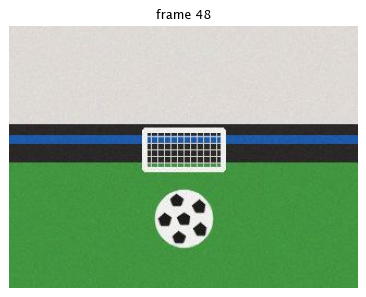

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.8))
ax.imshow(rgb(image))
ax.set_title(f"frame {FRAME}")
ax.axis("off")
plt.show()

## 2. Hue, saturation and brightness

The detector blurs the picture a little first (`blur_ksize` 3 smooths JPEG noise), then converts
it to HSV. Hue is the color itself, from 0 to 179 in OpenCV, so red sits at both ends.
Saturation is how strong the color is, and value is how bright. A white ball has low saturation
and high value, whatever its hue.

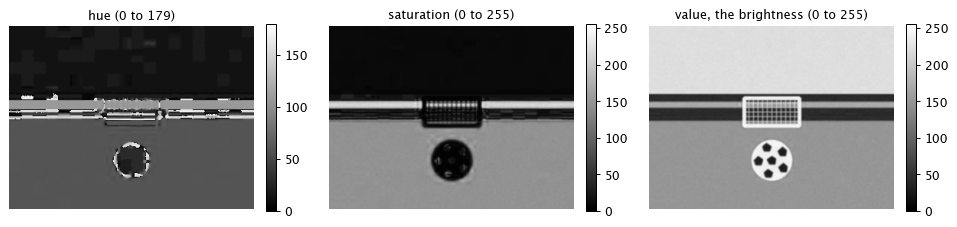

In [4]:
blurred = image
if BALL.blur_ksize > 1:
    blurred = cv2.GaussianBlur(image, (BALL.blur_ksize, BALL.blur_ksize), 0)
hsv = cv2.cvtColor(blurred, cv2.COLOR_BGR2HSV)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
names = ["hue (0 to 179)", "saturation (0 to 255)", "value, the brightness (0 to 255)"]
for channel, (ax, name, top) in enumerate(zip(axes, names, (179, 255, 255))):
    shown = ax.imshow(hsv[..., channel], cmap="gray", vmin=0, vmax=top)
    ax.set_title(name)
    ax.axis("off")
    fig.colorbar(shown, ax=ax, fraction=0.035)
plt.show()

## 3. The color mask

Each HSV range keeps the pixels inside it, and several ranges are added together. On the fake
video the ball's one range is white: saturation at most 90 and value at least 150, any hue. White
in the mask means "this pixel matched". The room wall and the goal match too, which is why the
next step exists.

the ball's HSV ranges: [{'lower': [0, 0, 150], 'upper': [179, 90, 255]}]
32082 pixels match


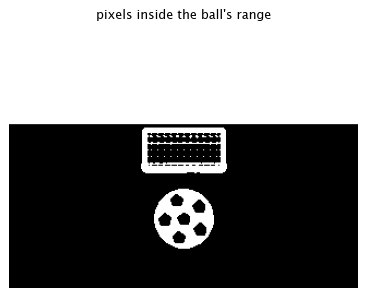

In [5]:
color_mask = np.zeros(hsv.shape[:2], dtype=np.uint8)
for r in BALL.hsv_ranges:
    color_mask |= cv2.inRange(hsv, np.array(r.lower, np.uint8), np.array(r.upper, np.uint8))
print("the ball's HSV ranges:", [r.to_dict() for r in BALL.hsv_ranges])
print(f"{int(np.count_nonzero(color_mask))} pixels match")

fig, ax = plt.subplots(figsize=(5, 3.8))
ax.imshow(color_mask, cmap="gray")
ax.set_title("pixels inside the ball's range")
ax.axis("off")
plt.show()

## 4. The search band

The search band keeps only the rows where a ball on the floor can be, from `roi_top_frac` of
the height down to `roi_bottom_frac`, and blanks everything else. For the ball that is 0.57 to
1.0, rows 137 to the bottom, which starts below the goal's base.

search band: rows 137 to 239


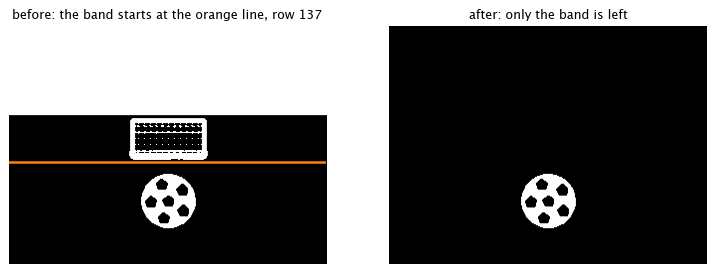

In [6]:
h = color_mask.shape[0]
top, bottom = int(round(BALL.roi_top_frac * h)), int(round(BALL.roi_bottom_frac * h))
banded = color_mask.copy()
banded[:top] = 0
banded[bottom:] = 0
print(f"search band: rows {top} to {bottom - 1}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].imshow(color_mask, cmap="gray")
axes[0].axhline(top, color="tab:orange", linewidth=2)
axes[0].set_title(f"before: the band starts at the orange line, row {top}")
axes[1].imshow(banded, cmap="gray")
axes[1].set_title("after: only the band is left")
for ax in axes:
    ax.axis("off")
plt.show()

## 5. The cleanup

Morphology tidies the mask with a small round brush. Opening (shrink, then grow) would remove
specks, but the ball's `open_ksize` is 0, so it is skipped. Closing (grow, then shrink) fills
small gaps and holes, with a `close_ksize` of 5. The bigger black patches on this ball stay as
holes, and that is fine: the next step looks only at each blob's outline. Closing can grow a
blob back over the band edge, so the band is applied once more.

The check at the end compares this step-by-step mask with the real `ColorDetector.mask()`,
pixel for pixel.

matches ColorDetector.mask() pixel for pixel: 1764 pixels


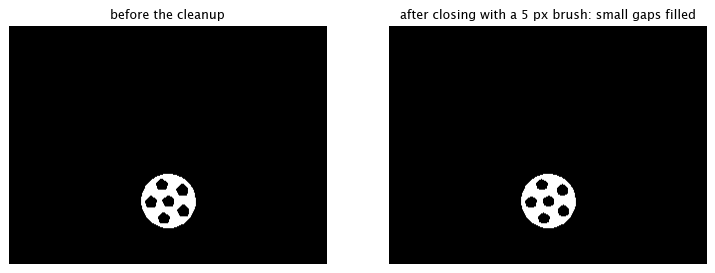

In [7]:
def brush(size):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size)) if size > 1 else None


cleaned = banded.copy()
if brush(BALL.open_ksize) is not None:
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_OPEN, brush(BALL.open_ksize))
if brush(BALL.close_ksize) is not None:
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, brush(BALL.close_ksize))
cleaned[:top] = 0
cleaned[bottom:] = 0

real_mask = ColorDetector(BALL).mask(image)
assert np.array_equal(cleaned, real_mask), "these steps no longer match ColorDetector.mask()"
print(f"matches ColorDetector.mask() pixel for pixel: {int(np.count_nonzero(cleaned))} pixels")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].imshow(banded, cmap="gray")
axes[0].set_title("before the cleanup")
axes[1].imshow(cleaned, cmap="gray")
axes[1].set_title(f"after closing with a {BALL.close_ksize} px brush: small gaps filled")
for ax in axes:
    ax.axis("off")
plt.show()

## 6. Every blob and its scores

The detector traces the outline of every white blob left in the mask and checks each one. It
must be big enough (`min_area_px`) and not too big (`max_area_frac` of the picture). Its pixels
are counted with the outline filled in, so holes inside don't count against it. Fill is those
pixels over the pixels of the smallest circle around the blob, and must reach `min_fill_ratio`. A blob with a radius of `circularity_min_radius_px` or more must also be round:
circularity, 4πA/P² on its convex hull, is 1 for a perfect circle. A blob that passes scores its
quality times its area, and the highest score wins.

blob  pixels  fill  round  verdict                score
   0    2355  1.00   0.99  passes                 2338
the winner matches ColorDetector.analyze(): x=160.0, y=176.0, radius=27.5


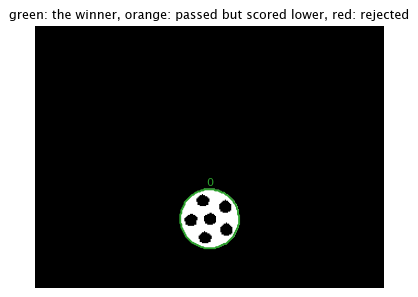

In [8]:
contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
H, W = cleaned.shape
blobs = []
for contour in contours:
    bx, by, bw, bh = cv2.boundingRect(contour)
    filled = np.zeros_like(cleaned)
    cv2.drawContours(filled, [contour], -1, 255, thickness=cv2.FILLED)
    pixels = int(np.count_nonzero(filled))
    (cx, cy), r = cv2.minEnclosingCircle(contour)
    circle = np.zeros_like(cleaned)
    cv2.circle(circle, (int(round(cx)), int(round(cy))), int(round(r)), 255, thickness=-1)
    fill = min(1.0, pixels / max(int(np.count_nonzero(circle)), 1))
    hull = cv2.convexHull(contour)
    perimeter = cv2.arcLength(hull, True)
    roundness = min(1.0, 4 * np.pi * cv2.contourArea(hull) / perimeter**2) if perimeter > 0 else 0.0
    checks_roundness = r >= BALL.circularity_min_radius_px
    if bw * bh < BALL.min_area_px or pixels < BALL.min_area_px:
        verdict = "too small"
    elif pixels > BALL.max_area_frac * W * H:
        verdict = "too big"
    elif fill < BALL.min_fill_ratio:
        verdict = f"fill under {BALL.min_fill_ratio}"
    elif checks_roundness and roundness < BALL.min_circularity:
        verdict = f"roundness under {BALL.min_circularity}"
    else:
        verdict = "passes"
    quality = fill * roundness if checks_roundness else fill
    score = quality * pixels if verdict == "passes" else 0.0
    blobs.append({"contour": contour, "x": cx, "y": cy, "r": r, "pixels": pixels, "fill": fill,
                  "roundness": roundness, "verdict": verdict, "score": score})

print(f"{'blob':>4} {'pixels':>7} {'fill':>5} {'round':>6}  {'verdict':<22} score")
for i, b in enumerate(blobs):
    print(f"{i:>4} {b['pixels']:>7} {b['fill']:>5.2f} {b['roundness']:>6.2f}  {b['verdict']:<22} {b['score']:.0f}")

passing = [b for b in blobs if b["verdict"] == "passes"]
winner = max(passing, key=lambda b: b["score"]) if passing else None
found, _ = ColorDetector(BALL).analyze(image)
assert found.found == (winner is not None), "the pick no longer matches ColorDetector.analyze()"
if winner is not None:
    assert abs(found.x - winner["x"]) < 1e-6 and abs(found.radius - winner["r"]) < 1e-6
    print(f"the winner matches ColorDetector.analyze(): x={found.x:.1f}, y={found.y:.1f}, radius={found.radius:.1f}")

fig, ax = plt.subplots(figsize=(5, 3.8))
ax.imshow(cleaned, cmap="gray")
for i, b in enumerate(blobs):
    color = "tab:green" if b is winner else ("tab:orange" if b["verdict"] == "passes" else "tab:red")
    outline = b["contour"][:, 0, :]
    ax.plot(outline[:, 0], outline[:, 1], color=color, linewidth=1.5)
    ax.text(b["x"], b["y"] - b["r"] - 3, str(i), color=color, ha="center", fontsize=9)
ax.set_title("green: the winner, orange: passed but scored lower, red: rejected")
ax.axis("off")
plt.show()

## 7. The circle it picks

The winner's center and radius are what the controller gets. On the fake video the true
position is known, so the two can be compared.

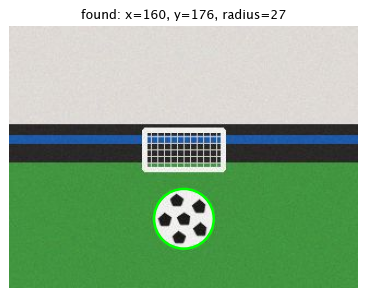

true position: x=160, y=176, radius=26


In [9]:
fig, ax = plt.subplots(figsize=(5, 3.8))
ax.imshow(rgb(image))
if found.found:
    ax.add_patch(plt.Circle((found.x, found.y), found.radius, fill=False, color="lime", linewidth=2))
    ax.set_title(f"found: x={found.x:.0f}, y={found.y:.0f}, radius={found.radius:.0f}")
else:
    ax.set_title("no ball found")
ax.axis("off")
plt.show()

if truth and truth[FRAME]["ball"]:
    tx, ty, tr = truth[FRAME]["ball"]
    print(f"true position: x={tx:.0f}, y={ty:.0f}, radius={tr:.0f}")
    assert found.found and abs(found.x - tx) <= max(2.0, 0.1 * tr)

## 8. The goal

The goal detector runs the same steps with its own settings: the same white range, a band from
0.38 to 0.8 of the height, a bigger closing brush (11 px) that joins the net into one blob, and
a box shape instead of a round one. A box must be 1.2 to 6 times wider than it is tall, and fill
at least 30% of its bounding box.

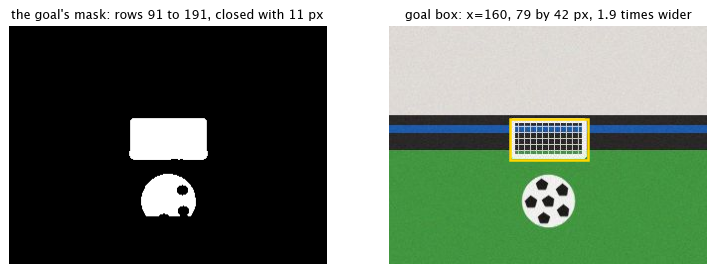

the goal sits where the fake video put it, x = 160.0


In [10]:
goal, goal_mask = ColorDetector(GOAL).analyze(image)
g_top, g_bottom = int(round(GOAL.roi_top_frac * h)), int(round(GOAL.roi_bottom_frac * h))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].imshow(goal_mask, cmap="gray")
axes[0].set_title(f"the goal's mask: rows {g_top} to {g_bottom - 1}, closed with 11 px")
axes[1].imshow(rgb(image))
if goal.found:
    corner = (goal.x - goal.width / 2, goal.y - goal.height / 2)
    axes[1].add_patch(plt.Rectangle(corner, goal.width, goal.height, fill=False, color="gold", linewidth=2))
    axes[1].set_title(f"goal box: x={goal.x:.0f}, {goal.width:.0f} by {goal.height:.0f} px, {goal.width / goal.height:.1f} times wider")
for ax in axes:
    ax.axis("off")
plt.show()

if truth and truth[FRAME]["goal_x"] is not None:
    assert goal.found and abs(goal.x - truth[FRAME]["goal_x"]) <= 3
    print("the goal sits where the fake video put it, x =", truth[FRAME]["goal_x"])

## 9. The red ball's two hue ranges

Hue is an angle, and OpenCV squeezes it into 0 to 179, so red sits at both ends. The `red_ball`
preset therefore has two ranges. A red ball of hue 2 matches only the low one, one of hue 177
only the high one, and with both ranges both are found.

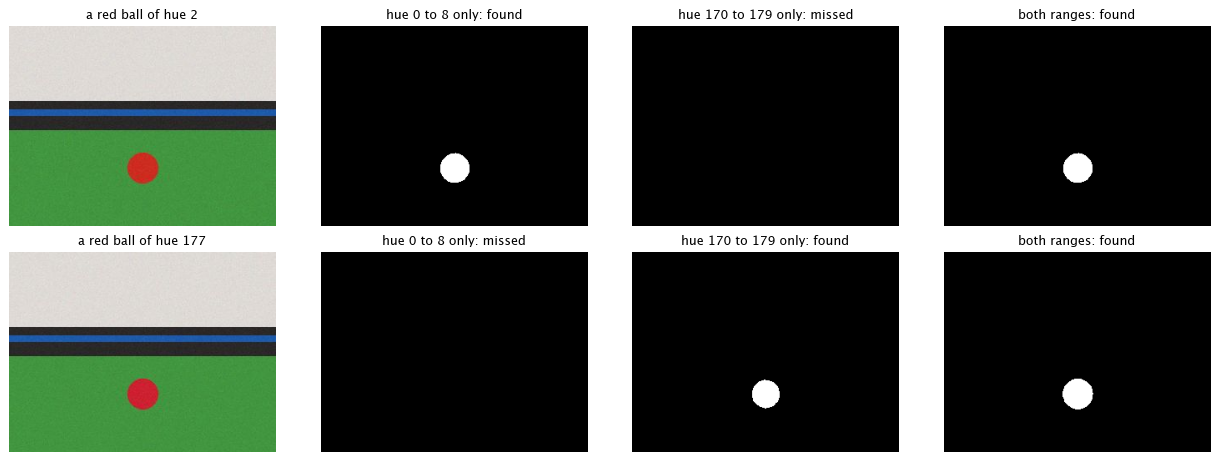

In [11]:
rng = np.random.default_rng(3)
red = DetectorConfig.from_dict(PRESETS["red_ball"])
low, high = red.hsv_ranges
options = [
    (replace(red, hsv_ranges=(low,)), f"hue {low.lower[0]} to {low.upper[0]} only"),
    (replace(red, hsv_ranges=(high,)), f"hue {high.lower[0]} to {high.upper[0]} only"),
    (red, "both ranges"),
]
fig, axes = plt.subplots(2, 4, figsize=(14, 5.2))
results = {}
for row, hue in enumerate((2, 177)):
    picture = syn.field()
    syn.draw_red_ball(picture, 160, 170, 18, hue)
    picture = syn.jpeg_roundtrip(syn.add_noise(picture, rng))
    axes[row, 0].imshow(rgb(picture))
    axes[row, 0].set_title(f"a red ball of hue {hue}")
    for col, (cfg, name) in enumerate(options, start=1):
        seen, mask = ColorDetector(cfg).analyze(picture)
        results[(hue, name)] = seen.found
        axes[row, col].imshow(mask, cmap="gray")
        axes[row, col].set_title(f"{name}: {'found' if seen.found else 'missed'}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

assert results[(2, "both ranges")] and results[(177, "both ranges")]
assert not results[(2, options[1][1])] and not results[(177, options[0][1])]

## 10. The band bug fixed on Oct 22

Frame 35 of the fake video has a far ball right under the goal. If the ball's band started
where the goal's band starts (0.38 of the height), the goal's bottom bar and the ball would sit
in the same mask, and closing would bridge the few pixels between them: one merged blob, too
square to pass as a ball, so no ball at all. Starting the band at 0.57, below the goal's base,
keeps them apart. Commit `cde0a62` made that change.

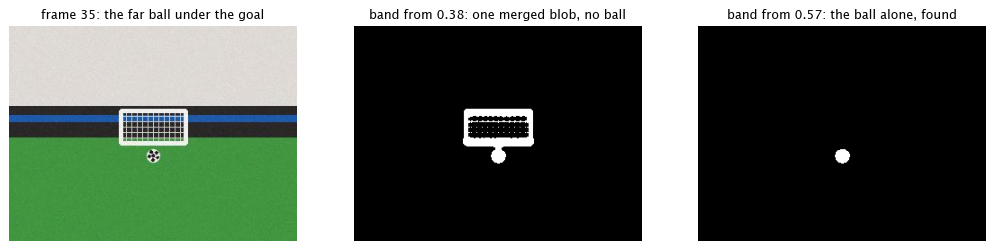

In [12]:
if truth:
    far = frames[35]
    before = replace(BALL, roi_top_frac=GOAL.roi_top_frac)
    seen_before, mask_before = ColorDetector(before).analyze(far)
    seen_now, mask_now = ColorDetector(BALL).analyze(far)
    assert not seen_before.found and seen_now.found

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    axes[0].imshow(rgb(far))
    axes[0].set_title("frame 35: the far ball under the goal")
    axes[1].imshow(mask_before, cmap="gray")
    axes[1].set_title(f"band from {before.roi_top_frac}: one merged blob, no ball")
    axes[2].imshow(mask_now, cmap="gray")
    axes[2].set_title(f"band from {BALL.roi_top_frac}: the ball alone, found")
    for ax in axes:
        ax.axis("off")
    plt.show()
else:
    print("The band bug is shown on the fake video; set SOURCE = 'synthetic' to see it.")